In [1]:
# ============================================================================
# 06a — SETUP FOR FIGURES 2-4
# ----------------------------------------------------------------------------
# Figure 1 is a hand-drawn schematic and is not produced by code.
# ============================================================================
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import binomtest

ROOT = Path.cwd().parent
PROC, RES = ROOT/"data"/"processed", ROOT/"results"
ONESIDED_CUTOFF = 0.85
A = pd.concat([pd.read_json(p, lines=True) for p in sorted(RES.glob("*.jsonl"))], ignore_index=True)
A = A[A.http==200].copy()
A["abstained"] = A.pred=="not_established"
A["committed"] = A.pred.isin(["stimulates","inhibits"])
A["correct"]   = A.pred.notna() & (A.pred==A.truth)
MAIN = A[(A.arm=="main") & ~A.is_decoy]; DEC = A[(A.arm=="main") & A.is_decoy]
SW, WEB, U = A[A.arm=="swap"], A[A.arm=="web"], A[A.arm=="usually"]
MODELS_ = sorted(MAIN.model.unique()); PROTS = sorted(MAIN.source.unique())
skew = {m: MAIN[(MAIN.model==m) & MAIN.committed].pred.value_counts(normalize=True).max() for m in MODELS_}
ONESIDED = [m for m in MODELS_ if skew[m] > ONESIDED_CUTOFF]
INFORM   = [m for m in MODELS_ if m not in ONESIDED]
def acc(d, c): return d[d.condition==c].correct.mean()
def gap(d, m=None):
    if m is not None: d = d[d.model==m]
    return (acc(d,"habit_agrees") - acc(d,"habit_misleads"))*100
FIG = ROOT/"figures"/"final_set"; FIG.mkdir(parents=True, exist_ok=True)
mpl.rcParams.update({
 "figure.dpi":120,"savefig.dpi":400,"savefig.bbox":"tight","savefig.pad_inches":0.15,
 "pdf.fonttype":42,"ps.fonttype":42,"font.family":"sans-serif",
 "font.sans-serif":["Arial","Helvetica","DejaVu Sans"],"font.size":8.5,
 "axes.titlesize":9.5,"axes.titleweight":"bold","axes.labelsize":8.5,
 "xtick.labelsize":7.8,"ytick.labelsize":7.8,"legend.fontsize":7.4,
 "axes.linewidth":0.7,"axes.spines.top":False,"axes.spines.right":False,
 "axes.grid":True,"grid.alpha":0.20,"grid.linewidth":0.5,"grid.color":"#9aa0a6",
 "legend.frameon":False,"axes.axisbelow":True})
INK, MUTE = "#2b2b2b", "#6b7280"
DEV={"gpt-5.6-terra":"OpenAI","gpt-5.6-luna":"OpenAI","gpt-oss-120b":"OpenAI",
 "gemini-3.7-flash":"Google","gemma-3-27b":"Google","gemma-4-31b":"Google",
 "medgemma-27b":"Google","claude-haiku-4.5":"Anthropic","llama-3-70b":"Meta",
 "llama-3.1-8b":"Meta","llama-3.3-70b":"Meta","mistral-large":"Mistral",
 "qwen3-32b":"Alibaba","qwen3-235b":"Alibaba","deepseek-v3":"DeepSeek","med42-70b":"M42"}
DEVCOL={"OpenAI":"#3E7C8C","Google":"#5B84C4","Anthropic":"#D98E73","Meta":"#8B7BB8",
 "Mistral":"#C27F86","Alibaba":"#D9B86B","DeepSeek":"#8A9BA3","M42":"#5E8F63"}
def col(m): return DEVCOL.get(DEV.get(m,""),"#9aa0a6")
LBL={"gemini-3.7-flash":"Gemini 3.7 Flash","gpt-5.6-terra":"GPT-5.6 Terra",
 "gpt-5.6-luna":"GPT-5.6 Luna","gpt-oss-120b":"GPT-OSS-120B","gemma-3-27b":"Gemma-3-27B",
 "gemma-4-31b":"Gemma-4-31B","medgemma-27b":"MedGemma-27B",
 "claude-haiku-4.5":"Claude Haiku 4.5","llama-3-70b":"Llama-3-70B",
 "llama-3.1-8b":"Llama-3.1-8B","llama-3.3-70b":"Llama-3.3-70B",
 "mistral-large":"Mistral Large","qwen3-32b":"Qwen3-32B","qwen3-235b":"Qwen3-235B",
 "deepseek-v3":"DeepSeek-V3","med42-70b":"Med42-70B"}
def lab(m): return LBL.get(m,m)
def save(f,n):
    for e in ("png","pdf","svg"): f.savefig(FIG/f"{n}.{e}")
    print(f"  saved {n}")
print(f"one-sided models (excluded from summaries): {ONESIDED}")

one-sided models (excluded from summaries): ['llama-3-70b', 'llama-3.1-8b']


  saved Fig2_main_result


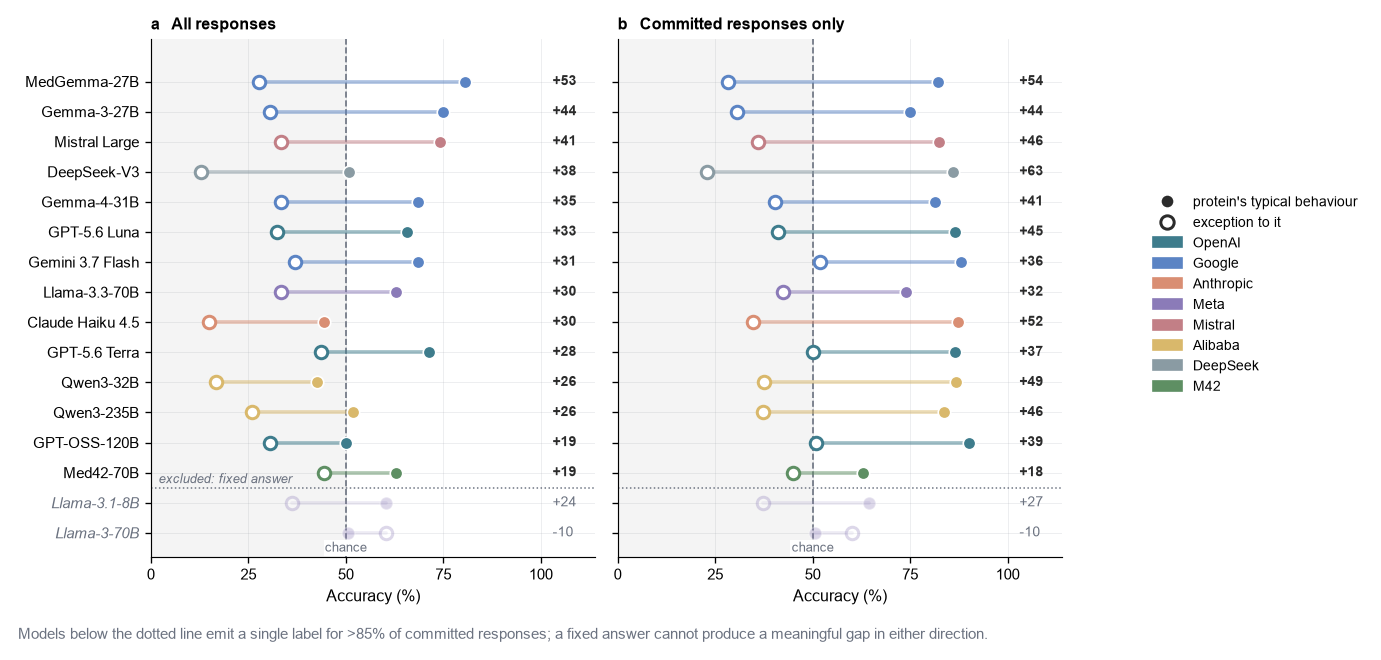

In [2]:
# ============================================================================
# 06b — FIGURE 2: MAIN RESULT
# ============================================================================
# excluded models are placed at the BOTTOM, not mixed into the ranking
order = sorted(ONESIDED,key=lambda m:gap(MAIN,m)) + sorted(INFORM,key=lambda m:gap(MAIN,m))
SEP = len(ONESIDED)-0.5          # boundary just above the excluded (bottom) models
fig,ax=plt.subplots(1,2,figsize=(9.8,5.6),sharey=True,gridspec_kw={"wspace":0.05})
for k,(only_c,ttl,sub) in enumerate([
    (False,"a   All responses","abstentions scored as incorrect"),
    (True ,"b   Committed responses only","abstentions excluded")]):
    ax[k].axvspan(0,50,color="#f4f4f4",zorder=0)
    ax[k].axvline(50,ls="--",lw=1.0,color=MUTE,zorder=1)
    ax[k].axhline(SEP,lw=.9,color=MUTE,ls=":",zorder=1)
    for i,m in enumerate(order):
        d=MAIN[MAIN.model==m]
        if only_c: d=d[d.committed]
        a,b_=acc(d,"habit_agrees")*100,acc(d,"habit_misleads")*100
        c=col(m); al=.30 if m in ONESIDED else 1.0
        ax[k].plot([b_,a],[i,i],lw=2.2,color=c,alpha=al*.5,solid_capstyle="round",zorder=2)
        ax[k].scatter(b_,i,s=56,marker="o",color="white",edgecolor=c,lw=1.8,zorder=3,alpha=al)
        ax[k].scatter(a,i,s=56,marker="o",color=c,edgecolor="white",lw=1.0,zorder=3,alpha=al)
        ax[k].text(103,i,f"{a-b_:+.0f}",va="center",fontsize=8.3,
                   color=MUTE if m in ONESIDED else INK,
                   fontweight="normal" if m in ONESIDED else "bold")
    # extra headroom so the subtitle sits above the top row instead of on it
    ax[k].set_xlim(0,114); ax[k].set_ylim(-0.8,len(order)+0.4)
    ax[k].set_xticks([0,25,50,75,100]); ax[k].set_xlabel("Accuracy (%)",fontsize=9.8)
    ax[k].tick_params(axis="both",labelsize=9.0)
    ax[k].set_title(ttl,loc="left")
        # "chance" centred on the dashed line, sitting just above the x-axis at 50
    ax[k].text(50,-0.72,"chance",fontsize=8.0,color=MUTE,ha="center",
               va="bottom",zorder=4,bbox=dict(fc="white",ec="none",pad=0.8))
ax[0].set_yticks(np.arange(len(order)))
ax[0].set_yticklabels([lab(m) for m in order],fontsize=9.0)
for t,m in zip(ax[0].get_yticklabels(),order):
    if m in ONESIDED: t.set_color(MUTE); t.set_fontstyle("italic")
# label sits just above the separator, over the excluded models
ax[0].text(2,SEP+0.06,"excluded: fixed answer",fontsize=7.8,color=MUTE,
           style="italic",va="bottom")
h=[Line2D([],[],marker="o",ls="",mfc=INK,mec="white",ms=8,label="protein's typical behaviour"),
   Line2D([],[],marker="o",ls="",mfc="white",mec=INK,mew=1.8,ms=8,label="exception to it")]
h+=[Patch(color=DEVCOL[d],label=d) for d in
    ["OpenAI","Google","Anthropic","Meta","Mistral","Alibaba","DeepSeek","M42"]]
# legend anchor moved 30% closer to the plot in total (measured from the right axes edge)
edge=ax[1].get_position().x1
fig.legend(handles=h,loc="center left",fontsize=8.5,
           bbox_to_anchor=(edge+0.70*(0.995-edge),0.5))
fig.text(0.012,-0.012,"Models below the dotted line emit a single label for >85% of "
   "committed responses; a fixed answer cannot produce a meaningful gap in either "
   "direction.",fontsize=9.0,color=MUTE)
save(fig,"Fig2_main_result"); plt.show()

  saved Fig3_controls


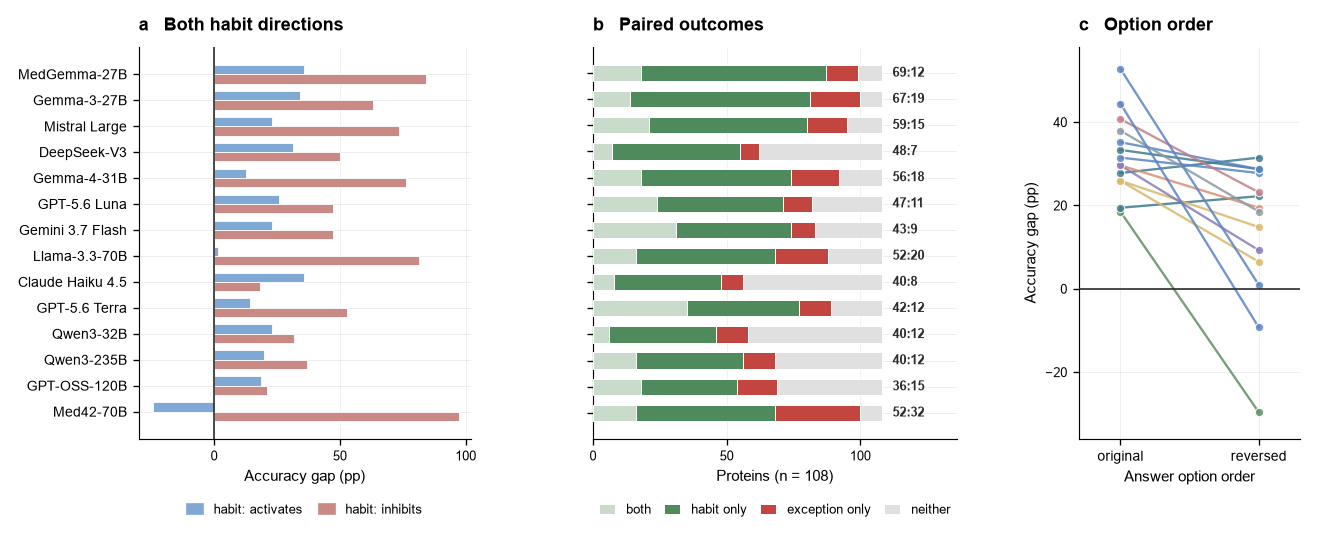

  for the legend: positive in 12/14, P = 0.013, median 31 -> 19 pp


In [3]:
# ============================================================================
# 06c — FIGURE 3: THE THREE CONTROLS
# ----------------------------------------------------------------------------
# Run after 06b. Needs: MAIN, SW, MODELS_, ONESIDED, col(), lab(), save(), FIG
# All explanatory text lives in the figure legend, not on the axes.
# ============================================================================
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import binomtest

INK, MUTE = "#2b2b2b", "#6b7280"
C_ACT, C_INH = "#7FA8D4", "#C98A86"
C_BOTH, C_HAB, C_EXC, C_NONE = "#C9DCCB", "#4E8A5B", "#C2453F", "#E0E0E0"

INFORM = [m for m in MODELS_ if m not in ONESIDED]
def _a(d, c): return d[d.condition == c].correct.mean()*100
def _gap(d, m=None):
    if m is not None: d = d[d.model == m]
    return _a(d, "habit_agrees") - _a(d, "habit_misleads")

order = sorted(INFORM, key=lambda m: _gap(MAIN, m))
y = np.arange(len(order))

fig, axes = plt.subplots(1, 3, figsize=(11.0, 4.8),
                         gridspec_kw={"width_ratios": [1.05, 1.15, 0.70],
                                      "wspace": 0.40})
fig.subplots_adjust(left=0.105, right=0.985, top=0.90, bottom=0.22)

# --------------------------------------------------------------- panel a --
ax = axes[0]; h = 0.36
for i, m in enumerate(order):
    for j, (u_, c_) in enumerate([("stimulates", C_ACT), ("inhibits", C_INH)]):
        d = MAIN[(MAIN.model == m) & (MAIN.protein_usually == u_)]
        ax.barh(i + (h/2 if j == 0 else -h/2), _gap(d), height=h,
                color=c_, edgecolor="white", lw=0.5, zorder=3)
ax.axvline(0, lw=1.0, color=INK, zorder=4)
ax.set_yticks(y); ax.set_yticklabels([lab(m) for m in order], fontsize=8.2)
ax.set_xlim(-30, 102); ax.set_xticks([0, 50, 100])
ax.set_xlabel("Accuracy gap (pp)", fontsize=9)
ax.set_title("a   Both habit directions", loc="left", fontsize=10.5,
             fontweight="bold", pad=10)
ax.grid(axis="x", alpha=0.18, lw=0.5); ax.set_axisbelow(True)
ax.legend(handles=[Patch(color=C_ACT, label="habit: activates"),
                   Patch(color=C_INH, label="habit: inhibits")],
          loc="upper center", bbox_to_anchor=(0.5, -0.135), ncol=2,
          fontsize=8, frameon=False, handlelength=1.2, columnspacing=1.2)

# --------------------------------------------------------------- panel b --
ax = axes[1]
rows = []
for m in order:
    p = (MAIN[MAIN.model == m].pivot_table(index="source", columns="condition",
         values="correct", aggfunc="first").dropna())
    rows.append(dict(both=int((p.habit_agrees & p.habit_misleads).sum()),
                     hab =int((p.habit_agrees & ~p.habit_misleads).sum()),
                     exc =int((~p.habit_agrees & p.habit_misleads).sum()),
                     none=int((~p.habit_agrees & ~p.habit_misleads).sum())))
P = pd.DataFrame(rows)
left = np.zeros(len(P))
for k_, c_, l_ in [("both", C_BOTH, "both"), ("hab", C_HAB, "habit only"),
                   ("exc", C_EXC, "exception only"), ("none", C_NONE, "neither")]:
    ax.barh(y, P[k_], left=left, height=0.62, color=c_,
            edgecolor="white", lw=0.6, label=l_, zorder=3)
    left = left + P[k_].values
for i, r in P.iterrows():
    ax.text(112, i, f"{r.hab}:{r.exc}", va="center", fontsize=7.8,
            color=INK, fontweight="bold")
ax.set_yticks(y); ax.set_yticklabels([])
ax.set_xlim(0, 136); ax.set_xticks([0, 50, 100])
ax.set_xlabel("Proteins (n = 108)", fontsize=9)
ax.set_title("b   Paired outcomes", loc="left", fontsize=10.5,
             fontweight="bold", pad=10)
ax.grid(axis="x", alpha=0.18, lw=0.5); ax.set_axisbelow(True)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.135), ncol=4,
          fontsize=8, frameon=False, handlelength=1.2, columnspacing=1.0)

# --------------------------------------------------------------- panel c --
ax = axes[2]
sw_g = []
for m in order:
    s = SW[SW.model == m]
    if not len(s): continue
    n = MAIN[(MAIN.model == m) & MAIN.item_id.isin(set(s.item_id))]
    gn, gs_ = _gap(n), _gap(s); sw_g.append(gs_)
    ax.plot([0, 1], [gn, gs_], lw=1.4, color=col(m), alpha=0.85,
            marker="o", ms=5, mec="white", mew=0.7, zorder=3)
ax.axhline(0, lw=1.0, color=INK, zorder=4)
ax.set_xlim(-0.30, 1.30); ax.set_xticks([0, 1])
ax.set_xticklabels(["original", "reversed"], fontsize=8.5)
ax.set_xlabel("Answer option order", fontsize=9)
ax.set_ylabel("Accuracy gap (pp)", fontsize=9)
ax.set_ylim(-36, 58)
ax.set_title("c   Option order", loc="left", fontsize=10.5,
             fontweight="bold", pad=10)
ax.grid(axis="y", alpha=0.18, lw=0.5); ax.set_axisbelow(True)

save(fig, "Fig3_controls"); plt.show()

k = sum(g > 0 for g in sw_g)
print(f"  for the legend: positive in {k}/{len(sw_g)}, "
      f"P = {binomtest(k, len(sw_g), 0.5).pvalue:.3f}, "
      f"median {np.median([_gap(MAIN,m) for m in order]):.0f} -> {np.median(sw_g):.0f} pp")

  saved Fig4_mechanism


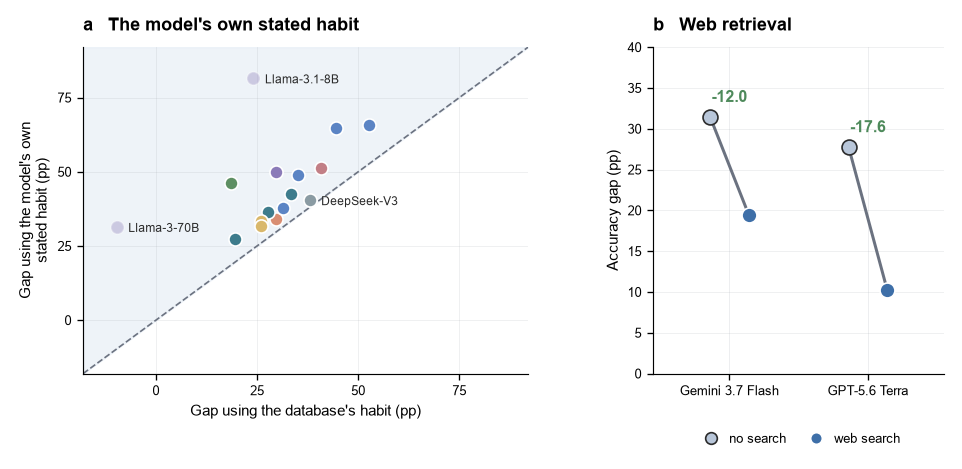

  panel a: 16 models, 16 above the diagonal, difference 2.5 to 57.4
  panel b: gemini-3.7-flash 31.5 -> 19.4
  panel b: gpt-5.6-terra 27.8 -> 10.2


In [4]:
# ============================================================================
# 06d — FIGURE 4: THE MODEL'S OWN HABIT, AND WEB RETRIEVAL
# ----------------------------------------------------------------------------
# Run after 06b. Needs: MAIN, U, WEB, MODELS_, ONESIDED, col(), lab(), save()
# All explanatory text lives in the figure legend, not on the axes.
# ============================================================================
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

INK, MUTE = "#2b2b2b", "#6b7280"
C_BASE, C_BIO, C_NONE, C_WEB = "#B8C6D9", "#C2453F", "#B8C6D9", "#3E6FA8"

INFORM = [m for m in MODELS_ if m not in ONESIDED]
def _a(d, c): return d[d.condition == c].correct.mean()*100
def _gap(d, m=None):
    if m is not None: d = d[d.model == m]
    return _a(d, "habit_agrees") - _a(d, "habit_misleads")

fig, axes = plt.subplots(1, 2, figsize=(8.2, 4.0),
                         gridspec_kw={"width_ratios": [1.30, 0.85], "wspace": 0.34})
fig.subplots_adjust(left=0.11, right=0.985, top=0.88, bottom=0.20)

# --------------------------------------------------------------- panel a --
ax = axes[0]
pts = []
for m in MODELS_:
    db = _gap(MAIN, m)
    u = U[U.model == m][["source", "pred"]].rename(columns={"pred": "own"})
    g = MAIN[MAIN.model == m].merge(u, on="source", how="left")
    g = g[g.own.isin(["stimulates", "inhibits"])]
    own = (g[g.truth == g.own].correct.mean()
           - g[g.truth != g.own].correct.mean())*100
    pts.append((m, db, own))
    ax.scatter(db, own, s=62, color=col(m), edgecolor="white", lw=1.0,
               zorder=3, alpha=0.35 if m in ONESIDED else 1.0)

lim = (-18, 92)
ax.plot(lim, lim, ls="--", lw=1.0, color=MUTE, zorder=1)
ax.fill_between(lim, lim, [lim[1]]*2, color="#EAF0F7", alpha=0.8, zorder=0)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xticks([0, 25, 50, 75]); ax.set_yticks([0, 25, 50, 75])
ax.set_xlabel("Gap using the database's habit (pp)", fontsize=9)
ax.set_ylabel("Gap using the model's own\nstated habit (pp)", fontsize=9)
ax.set_title("a   The model's own stated habit", loc="left",
             fontsize=10.5, fontweight="bold", pad=10)
ax.grid(alpha=0.18, lw=0.5); ax.set_axisbelow(True)

# label the four extremes only, so the panel stays readable
P = pd.DataFrame(pts, columns=["m", "db", "own"])
P["d"] = P.own - P.db
for _, r in pd.concat([P.nlargest(2, "d"), P.nlargest(1, "own"),
                       P.nsmallest(1, "d")]).drop_duplicates("m").iterrows():
    ax.annotate(lab(r.m), (r.db, r.own), textcoords="offset points",
                xytext=(7, -3), fontsize=7.4, color=INK)

# --------------------------------------------------------------- panel b --
ax = axes[1]
wm = sorted(WEB.model.unique())
for i, m in enumerate(wm):
    w = WEB[WEB.model == m]
    b = MAIN[(MAIN.model == m) & MAIN.item_id.isin(set(w.item_id))]
    gb, gw = _gap(b), _gap(w)
    ax.plot([i-0.14, i+0.14], [gb, gw], lw=1.8, color=MUTE, zorder=1)
    ax.scatter(i-0.14, gb, s=80, color=C_NONE, edgecolor=INK, lw=1.0, zorder=3)
    ax.scatter(i+0.14, gw, s=80, color=C_WEB, edgecolor="white", lw=1.0, zorder=3)
    ax.text(i, gb + 1.8, f"{gw-gb:+.1f}", ha="center", fontsize=9.5,
            fontweight="bold", color="#4E8A5B")
ax.set_xlim(-0.55, len(wm)-0.45); ax.set_xticks(range(len(wm)))
ax.set_xticklabels([lab(m) for m in wm], fontsize=8)
ax.set_ylabel("Accuracy gap (pp)", fontsize=9)
ax.set_ylim(0, 40)
ax.set_title("b   Web retrieval", loc="left", fontsize=10.5,
             fontweight="bold", pad=10)
ax.grid(axis="y", alpha=0.18, lw=0.5); ax.set_axisbelow(True)
ax.legend(handles=[Line2D([], [], marker="o", ls="", mfc=C_NONE, mec=INK,
                          ms=7, label="no search"),
                   Line2D([], [], marker="o", ls="", mfc=C_WEB, mec="white",
                          ms=7, label="web search")],
          loc="upper center", bbox_to_anchor=(0.5, -0.145), ncol=2,
          fontsize=8, frameon=False, handletextpad=0.4, columnspacing=1.2)

save(fig, "Fig4_mechanism"); plt.show()
print(f"  panel a: {len(P)} models, {int((P.d>0).sum())} above the diagonal, "
      f"difference {P.d.min():.1f} to {P.d.max():.1f}")
for m in wm:
    w = WEB[WEB.model==m]; b = MAIN[(MAIN.model==m)&MAIN.item_id.isin(set(w.item_id))]
    print(f"  panel b: {m} {_gap(b):.1f} -> {_gap(w):.1f}")


  saved supplementary/figures/FigS1_biomedical


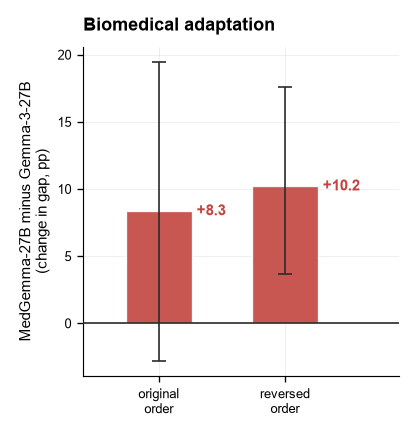

  MedGemma-27B minus Gemma-3-27B: original +8.3 (CI -2.8 to +19.4), reversed +10.2 (CI +3.7 to +17.6)


In [5]:
# ============================================================================
# 06e — SUPPLEMENTARY FIGURE S1: BIOMEDICAL ADAPTATION
# ----------------------------------------------------------------------------
# MedGemma-27B minus its base, Gemma-3-27B. Not significant in the original
# option order; the two models were served by different hosts. Supplement only.
# ============================================================================
SFIG = ROOT/"supplementary"/"figures"; SFIG.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(3.6, 3.8))
fig.subplots_adjust(left=0.24, right=0.97, top=0.88, bottom=0.16)
# MedGemma-27B vs its base, in both option orders, with 95% bootstrap CIs over
# proteins. The Med42 / Llama-3-70B pair is not shown: its base model is one-sided.
def _pairs(d):
    return d.pivot_table(index="source", columns="condition", values="correct",
                         aggfunc="first").reindex(PROTS).astype(float)
vals, los, his, labs_ = [], [], [], []
for nm, data in [("original\norder", MAIN), ("reversed\norder", SW)]:
    p1 = _pairs(data[data.model == "medgemma-27b"]); p0 = _pairs(data[data.model == "gemma-3-27b"])
    idx = np.random.default_rng(1).integers(0, len(PROTS), (4000, len(PROTS)))  # same draws as 04
    g = lambda p: (np.nanmean(p.habit_agrees.values[idx], 1) - np.nanmean(p.habit_misleads.values[idx], 1))*100
    bs = g(p1) - g(p0); v = _gap(data[data.model == "medgemma-27b"]) - _gap(data[data.model == "gemma-3-27b"])
    vals.append(v); los.append(v - np.percentile(bs, 2.5)); his.append(np.percentile(bs, 97.5) - v); labs_.append(nm)
ax.bar(range(2), vals, width=0.52, color=C_BIO, alpha=0.9, edgecolor="white", lw=0.8, zorder=3)
ax.errorbar(range(2), vals, yerr=[los, his], fmt="none", ecolor=INK, elinewidth=1.0, capsize=4, zorder=5)
for i, v in enumerate(vals):
    ax.text(i + 0.30, v, f"{v:+.1f}", ha="left", va="center", fontsize=9, fontweight="bold", color=C_BIO)
ax.axhline(0, lw=1.0, color=INK, zorder=4)
ax.set_xticks(range(2)); ax.set_xticklabels(labs_, fontsize=8)
ax.set_xlim(-0.6, 1.9)
ax.set_ylabel("MedGemma-27B minus Gemma-3-27B\n(change in gap, pp)", fontsize=9)
ax.set_title("Biomedical adaptation", loc="left", fontsize=10.5, fontweight="bold", pad=10)
ax.grid(axis="y", alpha=0.18, lw=0.5); ax.set_axisbelow(True)

for e in ("png", "pdf", "svg"): fig.savefig(SFIG/f"FigS1_biomedical.{e}")
print("  saved supplementary/figures/FigS1_biomedical"); plt.show()
print(f"  MedGemma-27B minus Gemma-3-27B: original {vals[0]:+.1f} (CI {vals[0]-los[0]:+.1f} to {vals[0]+his[0]:+.1f}), "
      f"reversed {vals[1]:+.1f} (CI {vals[1]-los[1]:+.1f} to {vals[1]+his[1]:+.1f})")
